In [3]:
import pandas as pd

# Load the datasets
vix_df = pd.read_csv('C:/Users/guosh/OneDrive/Desktop/mfams/VIXCLS_volatility.csv')
fx_df = pd.read_csv('C:/Users/guosh/OneDrive/Desktop/mfams/FXdataDaily_2005_to_2026_Dev_and_underdeve/daily.csv')

# Display the first few rows of each
print("VIX Volatility Data (first 5 rows):")
print(vix_df.head())

print("\nFX Daily Data (first 5 rows):")
print(fx_df.head())

VIX Volatility Data (first 5 rows):
  observation_date  VIXCLS
0       2005-01-03   14.08
1       2005-01-04   13.98
2       2005-01-05   14.09
3       2005-01-06   13.58
4       2005-01-07   13.49

FX Daily Data (first 5 rows):
  observation_date  DEXBZUS  DEXCAUS  DEXCHUS  DEXDNUS  DEXHKUS  DEXINUS  \
0       2005-01-03   2.6695   1.2108   8.2765   5.5161   7.7775    43.35   
1       2005-01-04   2.7020   1.2248   8.2765   5.5927   7.7851    43.47   
2       2005-01-05   2.6970   1.2236   8.2765   5.5959   7.7881    43.60   
3       2005-01-06   2.7190   1.2371   8.2765   5.6417   7.7935    43.75   
4       2005-01-07   2.7095   1.2333   8.2765   5.6951   7.7920    43.63   

   DEXJPUS  DEXKOUS  DEXMAUS  ...  DEXUSEU  DEXUSNZ  DEXUSUK  DEXVZUS  \
0   102.83   1038.0      3.8  ...   1.3476   0.7148   1.9058   1.9152   
1   104.27   1038.0      3.8  ...   1.3295   0.7069   1.8834   1.9152   
2   103.95   1046.3      3.8  ...   1.3292   0.7030   1.8875   1.9152   
3   104.87   1058.0   

In [4]:
# Convert VIXCLS column to numeric, handling missing or non-numeric values (coercing them to NaN)
vix_df['VIXCLS'] = pd.to_numeric(vix_df['VIXCLS'], errors='coerce')

# Filter the rows based on the threshold of 30
High_volatility = vix_df[vix_df['VIXCLS'] > 30].copy()
Medium_volatility = vix_df[(vix_df['VIXCLS'] <= 30) & (vix_df['VIXCLS'] > 15)].copy()
Low_volatility = vix_df[vix_df['VIXCLS'] <= 30].copy()

# Display the sizes and preview of each dataset
print(f"High Volatility shape: {High_volatility.shape}")
print(f"Low Volatility shape: {Medium_volatility.shape}")
print(f"Low Volatility shape: {Low_volatility.shape}")

print("\nHigh Volatility Preview:")
display(High_volatility.head())

print("\nMedium Volatility Preview:")
display(Medium_volatility.head())

print("\nLow Volatility Preview:")
display(Low_volatility.head())

High Volatility shape: (450, 2)
Low Volatility shape: (3045, 2)
Low Volatility shape: (5064, 2)

High Volatility Preview:


,observation_date,VIXCLS
682,2007-08-15,30.67
683,2007-08-16,30.83
745,2007-11-12,31.09
796,2008-01-22,31.01
834,2008-03-14,31.16



Medium Volatility Preview:


,observation_date,VIXCLS
74,2005-04-15,17.74
75,2005-04-18,16.56
77,2005-04-20,16.92
79,2005-04-22,15.38
83,2005-04-28,16.86



Low Volatility Preview:


,observation_date,VIXCLS
0,2005-01-03,14.08
1,2005-01-04,13.98
2,2005-01-05,14.09
3,2005-01-06,13.58
4,2005-01-07,13.49


In [5]:
import pandas as pd
import numpy as np

# Create a copy of the FX dataframe
fx_calc = fx_df.copy()

# Set observation_date as the index
if 'observation_date' in fx_calc.columns:
    fx_calc.set_index('observation_date', inplace=True)

# Ensure all currency exchange rate columns are numeric
for col in fx_calc.columns:
    fx_calc[col] = pd.to_numeric(fx_calc[col], errors='coerce')

# Calculate daily percentage returns
fx_returns = fx_calc.pct_change()

# Calculate the lag-1 autocorrelation for each currency pair return series
autocorrelations = {}
for col in fx_returns.columns:
    # Drop NaNs to calculate clean autocorrelation
    clean_returns = fx_returns[col].dropna()
    if len(clean_returns) > 1:
        autocorrelations[col] = clean_returns.autocorr(lag=1)
    else:
        autocorrelations[col] = np.nan

# Convert to a DataFrame for neat display
autocorr_df = pd.DataFrame.from_dict(autocorrelations, orient='index', columns=['Lag_1_Autocorrelation'])
autocorr_df.index.name = 'FX_Pair'
autocorr_df = autocorr_df.sort_values(by='Lag_1_Autocorrelation', ascending=False)

display(autocorr_df)

,Lag_1_Autocorrelation
FX_Pair,
DTWEXO,0.061244
DEXSZUS,0.042301
DTWEXEMEGS,0.039950
DEXSLUS,0.034746
DTWEXB,0.031868
DTWEXBGS,0.029748
DEXUSUK,0.028119
DEXTHUS,0.026458
DEXMAUS,0.023785


In [7]:
# Identify the dates for high and low volatility periods
high_vol_dates = High_volatility['observation_date'].values
low_vol_dates = Low_volatility['observation_date'].values

# Filter the FX daily returns (fx_returns) for these specific periods
# Note: fx_returns has 'observation_date' as its index
high_vol_returns = fx_returns.loc[fx_returns.index.isin(high_vol_dates)]
low_vol_returns = fx_returns.loc[fx_returns.index.isin(low_vol_dates)]

# Calculate lag-1 autocorrelation for both regimes
comparison_data = {}
for col in fx_returns.columns:
    # High Volatility Autocorrelation
    high_clean = high_vol_returns[col].dropna()
    high_corr = high_clean.autocorr(lag=1) if len(high_clean) > 1 else np.nan

    # Low Volatility Autocorrelation
    low_clean = low_vol_returns[col].dropna()
    low_corr = low_clean.autocorr(lag=1) if len(low_clean) > 1 else np.nan

    comparison_data[col] = {
        'High_Vol_Autocorr': high_corr,
        'Low_Vol_Autocorr': low_corr,
        'Difference_(High_minus_Low)': high_corr - low_corr if not (np.isnan(high_corr) or np.isnan(low_corr)) else np.nan
    }

# Convert to a DataFrame for analysis
comparison_df = pd.DataFrame.from_dict(comparison_data, orient='index')
comparison_df.index.name = 'FX_Pair'
comparison_df = comparison_df.sort_values(by='Difference_(High_minus_Low)', ascending=False)

display(comparison_df)

,High_Vol_Autocorr,Low_Vol_Autocorr,Difference_(High_minus_Low)
FX_Pair,,,
DEXINUS,0.083986,-0.036598,0.120584
DEXTHUS,0.129762,0.018470,0.111292
DEXJPUS,0.070795,-0.025517,0.096312
DEXCAUS,0.059992,-0.023857,0.083849
DEXUSEU,0.053638,-0.012917,0.066555
DEXSFUS,0.072247,0.006359,0.065888
DEXDNUS,0.047298,-0.009297,0.056594
DEXSLUS,0.069083,0.015167,0.053916
DEXKOUS,-0.000040,-0.047480,0.047440


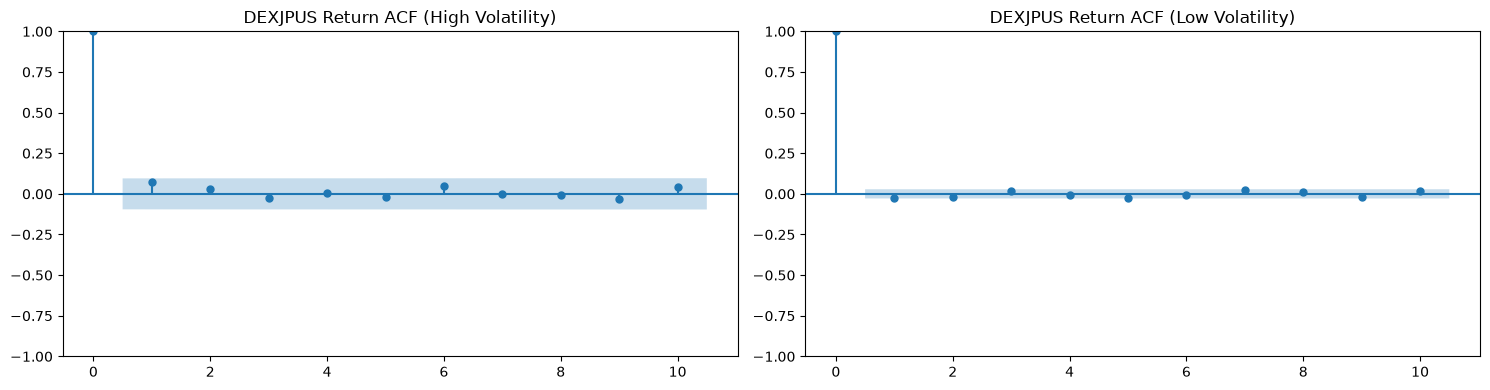

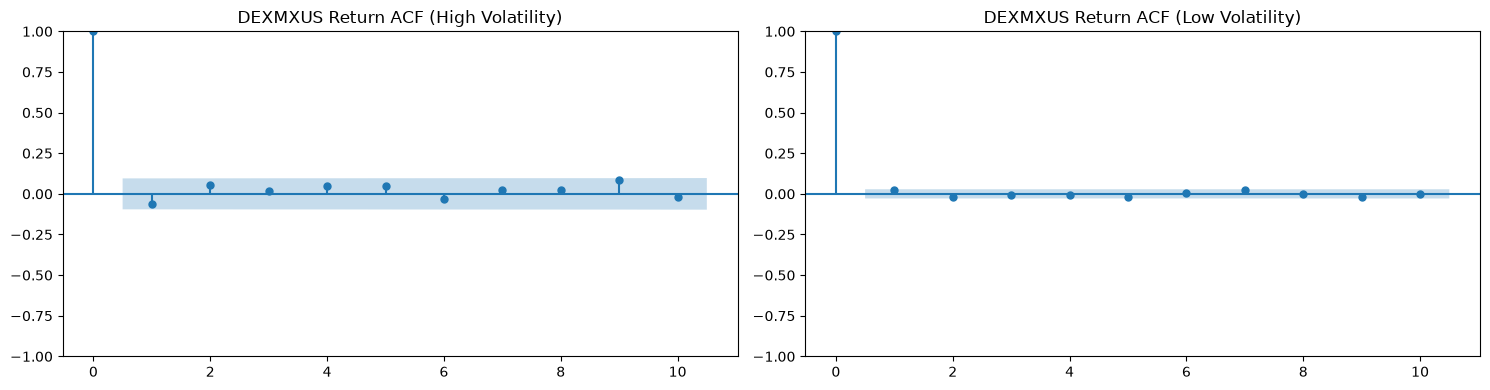

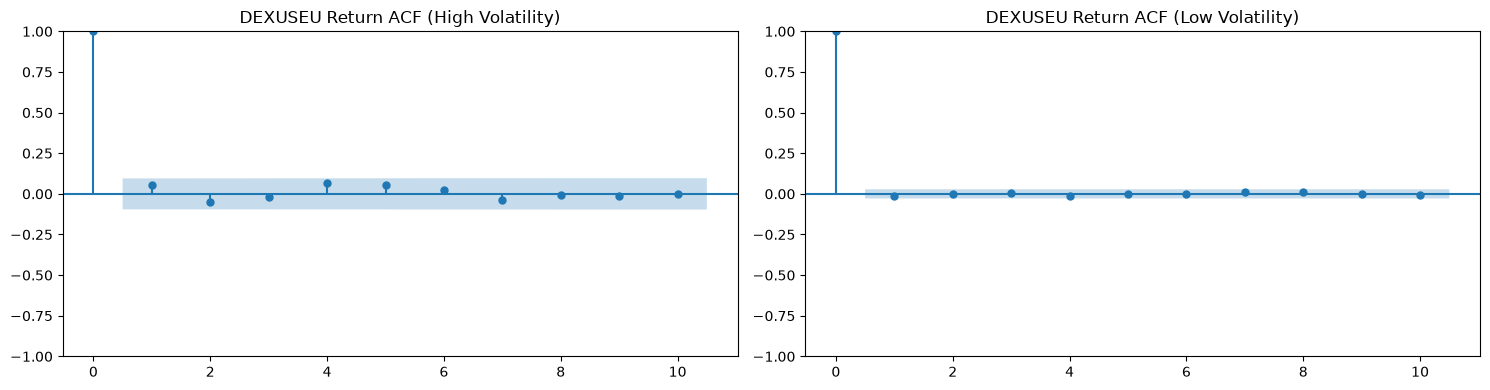

In [8]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# Select a few representative FX pairs to plot for comparison
# (e.g., DEXJPUS for safe-haven/momentum shift, DEXMXUS for emerging market/reversion shift)
selected_pairs = ['DEXJPUS', 'DEXMXUS', 'DEXUSEU']

for pair in selected_pairs:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))

    # Get clean return series for both regimes
    high_series = high_vol_returns[pair].dropna()
    low_series = low_vol_returns[pair].dropna()

    # Plot ACF for High Volatility
    if len(high_series) > 0:
        plot_acf(high_series, ax=axes[0], lags=10, title=f'{pair} Return ACF (High Volatility)')
    else:
        axes[0].set_title(f'{pair} (No Data for High Vol)')

    # Plot ACF for Low Volatility
    if len(low_series) > 0:
        plot_acf(low_series, ax=axes[1], lags=10, title=f'{pair} Return ACF (Low Volatility)')
    else:
        axes[1].set_title(f'{pair} (No Data for Low Vol)')

    plt.tight_layout()
    plt.show()

In [10]:
# Ensure we have clean daily returns calculated
fx_calc = fx_df.copy()
if 'observation_date' in fx_calc.columns:
    fx_calc.set_index('observation_date', inplace=True)

for col in fx_calc.columns:
    fx_calc[col] = pd.to_numeric(fx_calc[col], errors='coerce')

# Calculate daily percentage returns (ignoring deprecation warning behavior)
fx_returns = fx_calc.pct_change(fill_method=None)

# Helper function to compute rolling autocorrelation
def rolling_autocorr(series, window=30, lag=1):
    return series.rolling(window=window).apply(lambda x: x.autocorr(lag=lag) if len(x.dropna()) > lag else np.nan)

# Calculate rolling autocorrelations for all columns in fx_returns
rolling_autocorr_df = pd.DataFrame(index=fx_returns.index)

for col in fx_returns.columns:
    if fx_returns[col].notna().sum() > 30:
        rolling_autocorr_df[col] = rolling_autocorr(fx_returns[col], window=30, lag=1)

print("Rolling Lag-1 Autocorrelations Calculated Successfully. Preview:")
display(rolling_autocorr_df)

Rolling Lag-1 Autocorrelations Calculated Successfully. Preview:


,DEXBZUS,DEXCAUS,DEXCHUS,DEXDNUS,DEXHKUS,DEXINUS,DEXJPUS,DEXKOUS,DEXMAUS,DEXMXUS,...,DEXUSEU,DEXUSNZ,DEXUSUK,DEXVZUS,DTWEXAFEGS,DTWEXB,DTWEXBGS,DTWEXEMEGS,DTWEXM,DTWEXO
observation_date,,,,,,,,,,,,,,,,,,,,,
2005-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


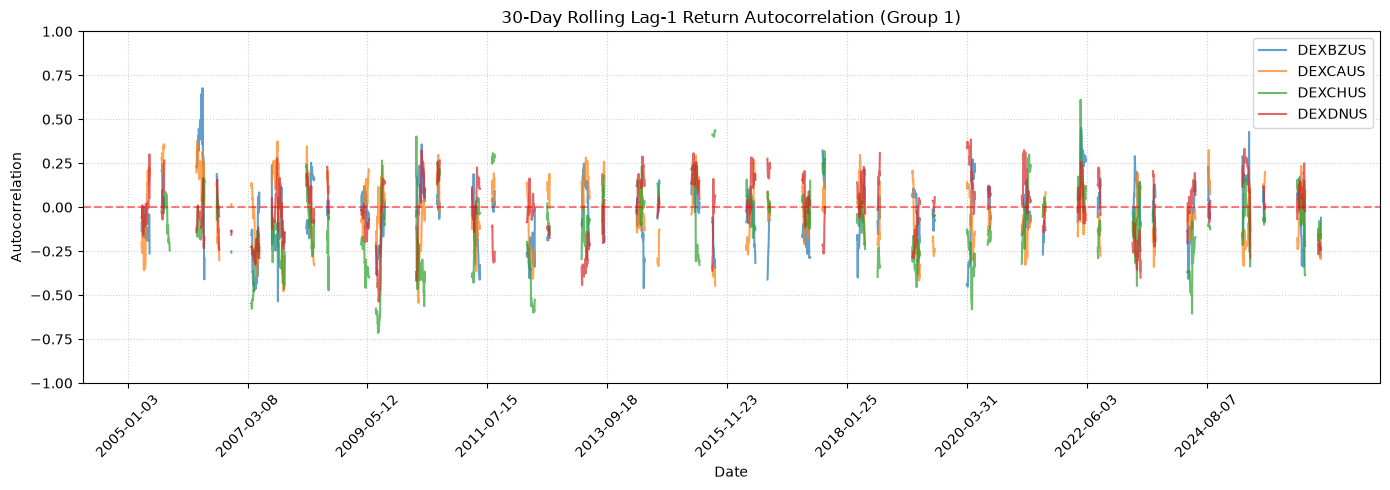

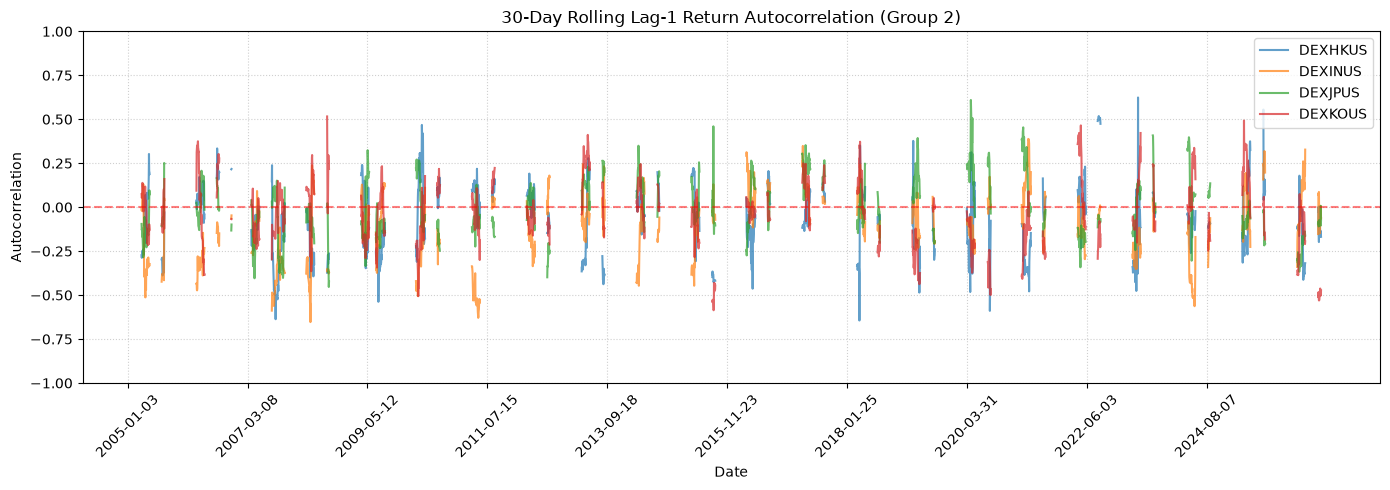

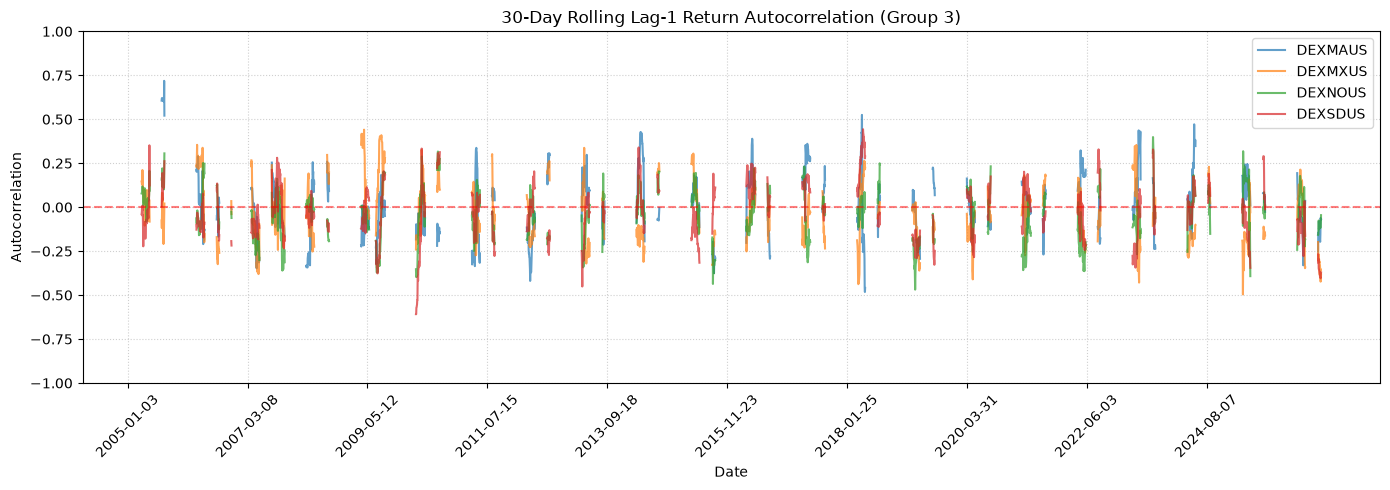

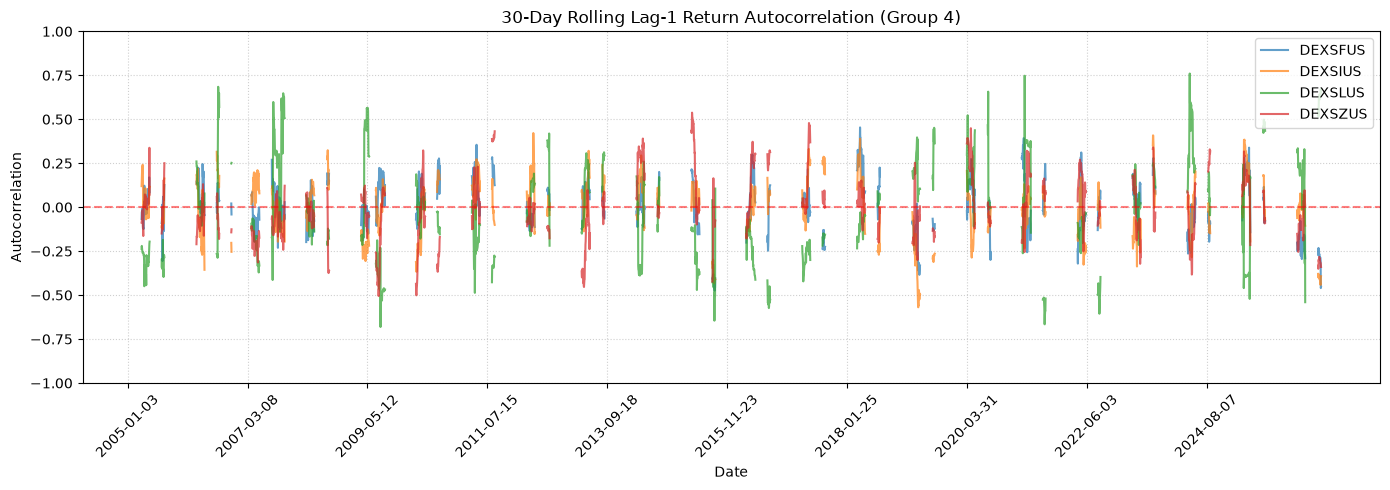

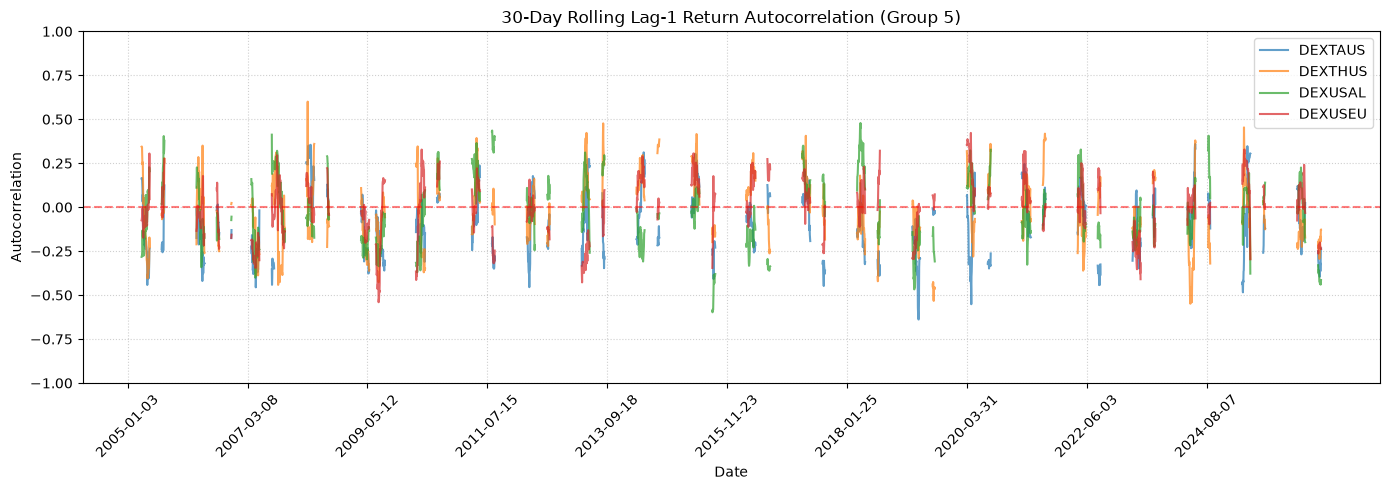

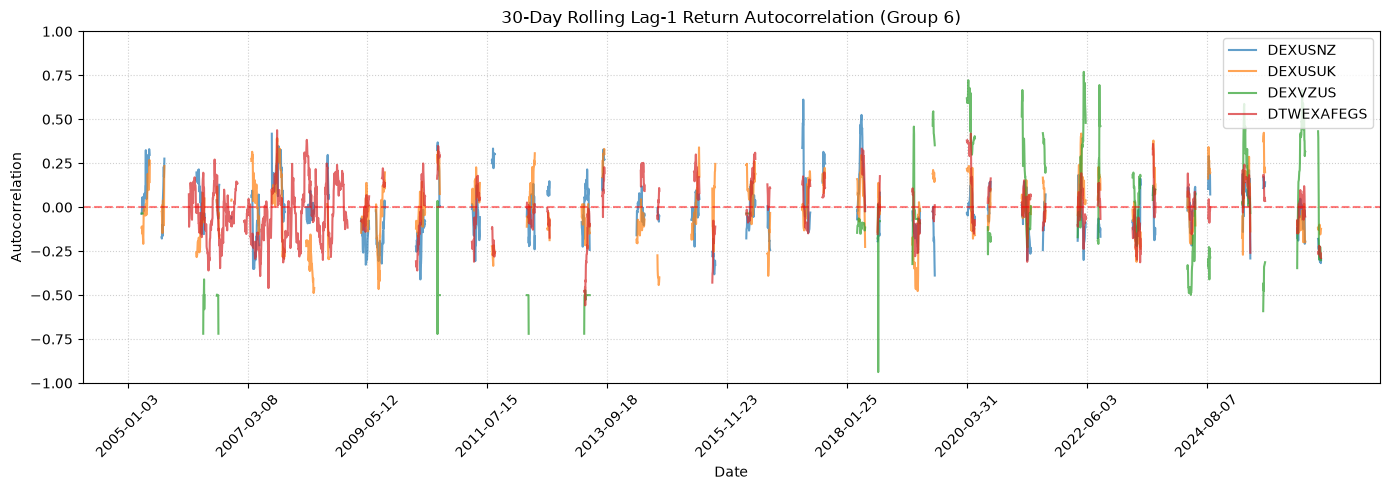

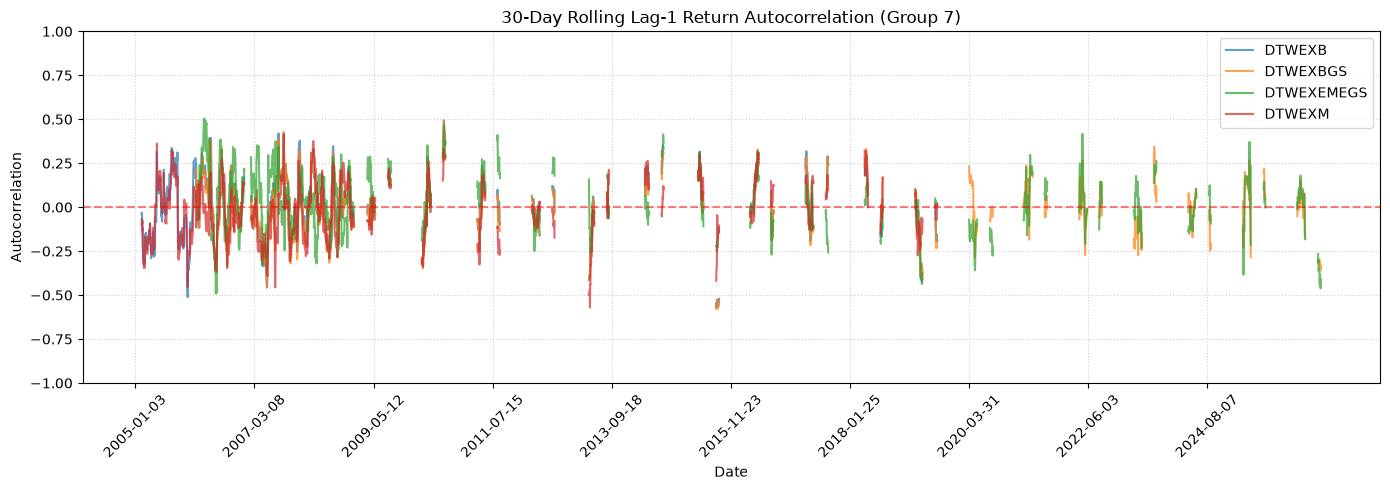

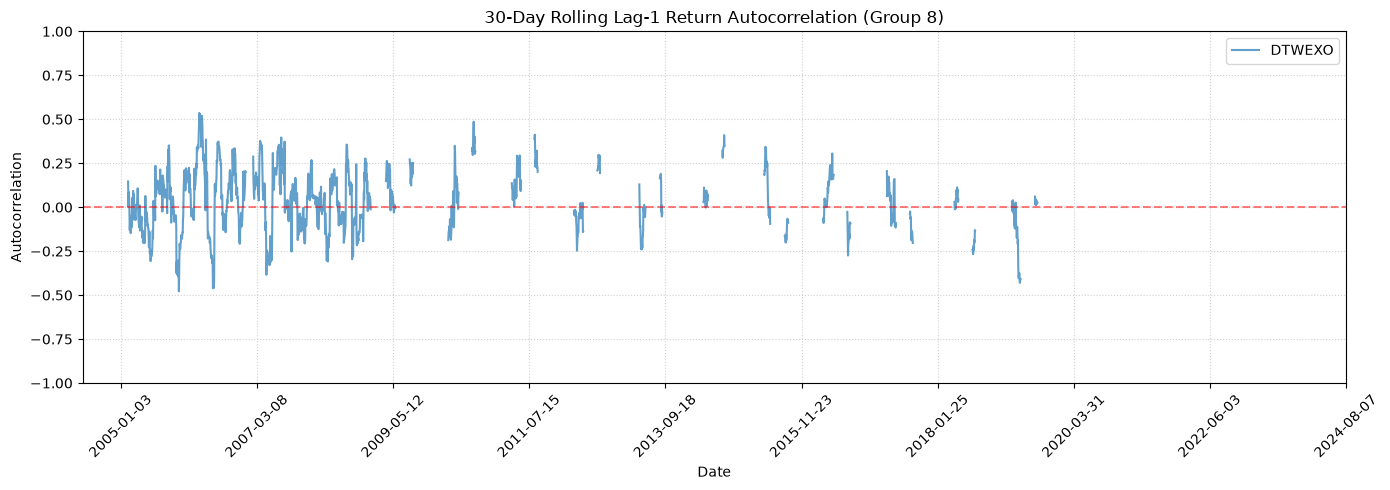

In [11]:
# Identify valid columns to plot
columns_to_plot = [col for col in rolling_autocorr_df.columns if not rolling_autocorr_df[col].isnull().all()]
batch_size = 4
num_batches = int(np.ceil(len(columns_to_plot) / batch_size))

# Plot rolling autocorrelations in small batches
for b in range(num_batches):
    batch_cols = columns_to_plot[b * batch_size : (b + 1) * batch_size]
    plt.figure(figsize=(14, 5))
    for col in batch_cols:
        plt.plot(rolling_autocorr_df.index, rolling_autocorr_df[col], label=col, alpha=0.7, linewidth=1.5)

    plt.title(f'30-Day Rolling Lag-1 Return Autocorrelation (Group {b+1})')
    plt.xlabel('Date')
    plt.ylabel('Autocorrelation')
    plt.axhline(0, color='red', linestyle='--', alpha=0.5)
    plt.ylim(-1, 1)
    plt.legend(loc='upper right')
    plt.grid(True, linestyle=':', alpha=0.6)

    # Display dates cleanly
    step = max(1, len(rolling_autocorr_df) // 10)
    plt.xticks(rolling_autocorr_df.index[::step], rotation=45)
    plt.tight_layout()
    plt.show()

,High Vol Regime Mean Absolute Error,Med Vol Regime Mean Absolute Error,Low Vol Regime Mean Absolute Error,High Vol Regime RMSE,Low Vol Regime RMSE
DEXJPUS,0.951115,0.397046,0.374115,2.244042,0.778631
DEXMXUS,2.247616,0.459051,0.443422,5.028241,1.121180
DEXUSEU,0.894160,0.282975,0.265505,1.788674,0.468984


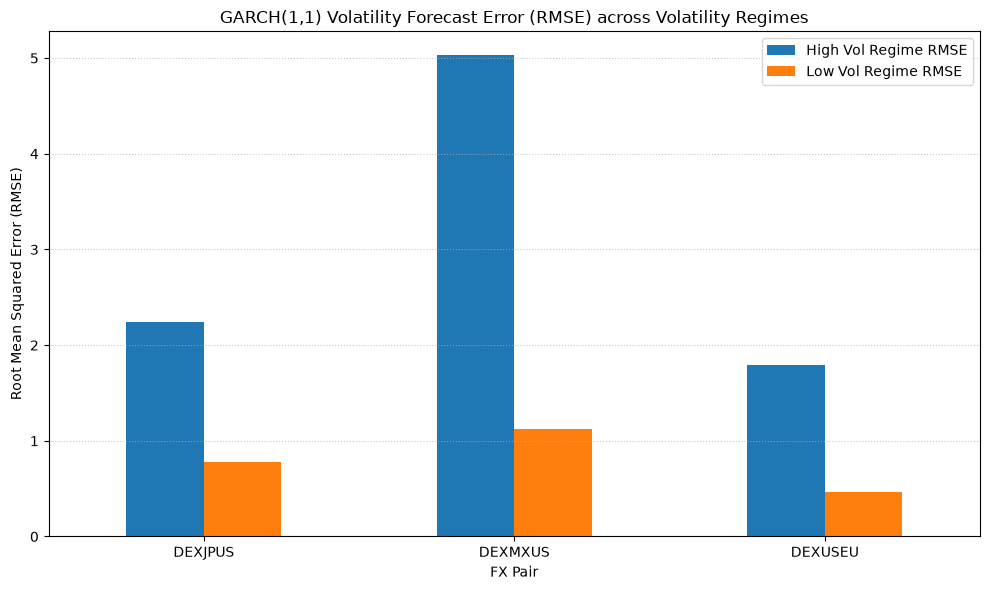

In [15]:
from arch import arch_model

# Define the representative currency pairs we want to analyze
selected_pairs = ['DEXJPUS', 'DEXMXUS', 'DEXUSEU']

# We will store forecast errors for each pair under different VIX regimes
comparison_results = {}

# Identify regime dates based on our VIX-based dataframes
high_vol_dates = set(High_volatility['observation_date'].values)
med_vol_dates = set(Medium_volatility['observation_date'].values)
low_vol_dates = set(Low_volatility['observation_date'].values)

for pair in selected_pairs:
    # Clean and scale returns to percentage
    returns_series = fx_returns[pair].dropna() * 100

    # Fit GARCH(1,1) model
    model = arch_model(returns_series, vol='Garch', p=1, q=1, dist='normal')
    fit_res = model.fit(disp='off')

    # Volatility forecast error:
    # Realized Volatility Proxy (Squared returns) minus GARCH predicted Conditional Variance
    realized_var = returns_series ** 2
    garch_var = fit_res.conditional_volatility ** 2
    forecast_error = (realized_var - garch_var)

    # Align forecast errors back to their original observation dates
    fe_df = pd.DataFrame({'Forecast_Error': forecast_error}, index=returns_series.index)

    # Segment the forecast errors into the VIX-based regimes
    high_errors = fe_df.loc[fe_df.index.isin(high_vol_dates), 'Forecast_Error'].dropna()
    med_errors = fe_df.loc[fe_df.index.isin(med_vol_dates), 'Forecast_Error'].dropna()
    low_errors = fe_df.loc[fe_df.index.isin(low_vol_dates), 'Forecast_Error'].dropna()

    comparison_results[pair] = {
        'High Vol Regime Mean Absolute Error': np.abs(high_errors).mean(),
        'Med Vol Regime Mean Absolute Error': np.abs(med_errors).mean(),
        'Low Vol Regime Mean Absolute Error': np.abs(low_errors).mean(),
        'High Vol Regime RMSE': np.sqrt((high_errors ** 2).mean()),
        'Low Vol Regime RMSE': np.sqrt((low_errors ** 2).mean())
    }

    # Convert results to DataFrame for display
comparison_errors_df = pd.DataFrame(comparison_results).T
display(comparison_errors_df)

# Plot the comparison of Root Mean Squared Volatility Forecast Errors
comparison_errors_df[['High Vol Regime RMSE', 'Low Vol Regime RMSE']].plot(kind='bar', figsize=(10, 6))
plt.title('GARCH(1,1) Volatility Forecast Error (RMSE) across Volatility Regimes')
plt.ylabel('Root Mean Squared Error (RMSE)')
plt.xlabel('FX Pair')
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()